In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    RocCurveDisplay
)

In [2]:
df = pd.read_csv("../data/raw/startup data.csv")

target = df["labels"]

columns_to_drop = [
    "Unnamed: 0",
    "Unnamed: 6",
    "id",
    "object_id",
    "name",
    "city",
    "zip_code",
    "state_code.1",
    "status",
    "labels",
    "closed_at",
    "founded_at",
    "first_funding_at",
    "last_funding_at"
]

X = df.drop(columns=columns_to_drop).copy()

X["funding_per_round"] = np.where(
    X["funding_rounds"] > 0,
    X["funding_total_usd"] / X["funding_rounds"],
    0
)

X["funding_duration_years"] = (
    X["age_last_funding_year"] - X["age_first_funding_year"]
)

X["advanced_funding_rounds"] = X[
    ["has_roundA", "has_roundB", "has_roundC", "has_roundD"]
].sum(axis=1)

print("Feature shape:", X.shape)
print("Target distribution:")
print(target.value_counts())

Feature shape: (923, 38)
Target distribution:
labels
1    597
0    326
Name: count, dtype: int64


In [10]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Numeric columns:", numeric_features)
print("Categorical columns:", categorical_features)

Numeric columns: ['latitude', 'longitude', 'age_first_funding_year', 'age_last_funding_year', 'age_first_milestone_year', 'age_last_milestone_year', 'relationships', 'funding_rounds', 'funding_total_usd', 'milestones', 'is_CA', 'is_NY', 'is_MA', 'is_TX', 'is_otherstate', 'is_software', 'is_web', 'is_mobile', 'is_enterprise', 'is_advertising', 'is_gamesvideo', 'is_ecommerce', 'is_biotech', 'is_consulting', 'is_othercategory', 'has_VC', 'has_angel', 'has_roundA', 'has_roundB', 'has_roundC', 'has_roundD', 'avg_participants', 'is_top500', 'funding_per_round', 'funding_duration_years', 'advanced_funding_rounds']
Categorical columns: ['state_code', 'category_code']


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (738, 38)
Testing data: (185, 38)


In [12]:
from sklearn.base import clone

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

trained_models = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [13]:
results = []
predictions = {}

for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "predictions": y_pred,
        "probabilities": y_prob
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.772973,0.791045,0.883333,0.834646,0.810769
1,Decision Tree,0.697297,0.780702,0.741667,0.760684,0.678526
0,Logistic Regression,0.681081,0.801980,0.675000,0.733032,0.786282


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

<Figure size 800x600 with 0 Axes>

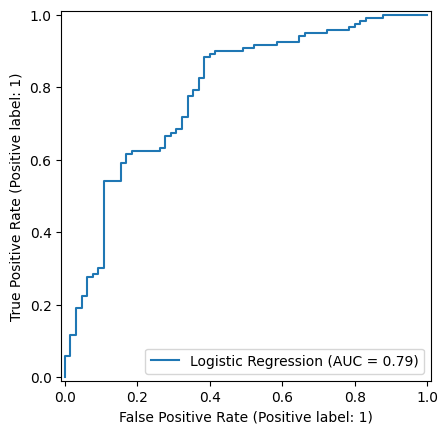

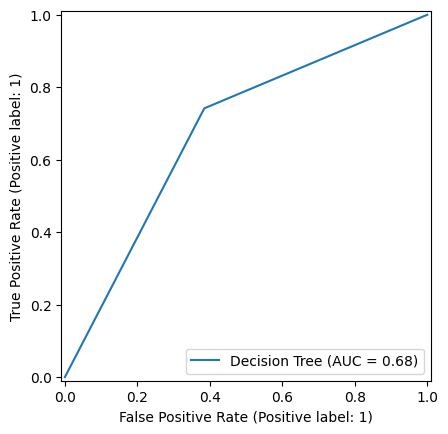

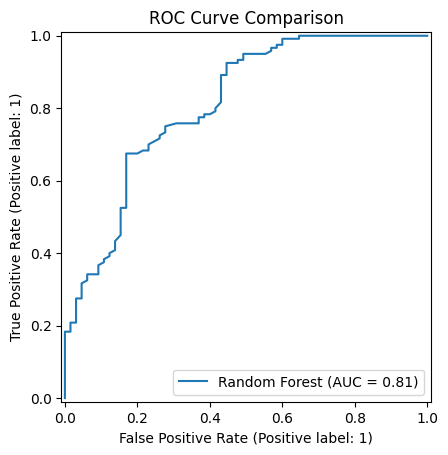

In [15]:
plt.figure(figsize=(8, 6))

for name, values in predictions.items():
    RocCurveDisplay.from_predictions(
        y_test,
        values["probabilities"],
        name=name
    )

plt.title("ROC Curve Comparison")
plt.show()

In [16]:
from sklearn.model_selection import GridSearchCVbest_model_name = results_df.iloc[0]["Model"]

best_y_pred = predictions[best_model_name]["predictions"]

best_cm = confusion_matrix(y_test, best_y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Closed", "Acquired"],
    yticklabels=["Closed", "Acquired"]
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.show()

SyntaxError: invalid syntax (219494552.py, line 1)

In [17]:
from sklearn.model_selection import GridSearchCV

In [18]:
tree_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

tree_parameters = {
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

tree_grid = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_parameters,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)

print("Best Decision Tree F1:", tree_grid.best_score_)
print("Best Decision Tree parameters:", tree_grid.best_params_)

Best Decision Tree F1: 0.7999562045448076
Best Decision Tree parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}


In [19]:
forest_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

forest_parameters = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

forest_grid = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=forest_parameters,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

forest_grid.fit(X_train, y_train)

print("Best Random Forest F1:", forest_grid.best_score_)
print("Best Random Forest parameters:", forest_grid.best_params_)

Best Random Forest F1: 0.8456064012766532
Best Random Forest parameters: {'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


In [20]:
tuned_models = {
    "Tuned Decision Tree": tree_grid.best_estimator_,
    "Tuned Random Forest": forest_grid.best_estimator_
}

tuned_results = []

for name, tuned_model in tuned_models.items():
    y_pred = tuned_model.predict(X_test)
    y_prob = tuned_model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

final_results_df = pd.concat(
    [results_df, tuned_results_df],
    ignore_index=True
).sort_values(by="F1-Score", ascending=False)

final_results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
4,Tuned Random Forest,0.778378,0.801527,0.875000,0.836653,0.809359
0,Random Forest,0.772973,0.791045,0.883333,0.834646,0.810769
3,Tuned Decision Tree,0.713514,0.791304,0.758333,0.774468,0.786731
1,Decision Tree,0.697297,0.780702,0.741667,0.760684,0.678526
2,Logistic Regression,0.681081,0.801980,0.675000,0.733032,0.786282


In [21]:
best_final_model_name = final_results_df.iloc[0]["Model"]

all_models = {
    **trained_models,
    **tuned_models
}

best_final_model = all_models[best_final_model_name]

print("Selected final model:", best_final_model_name)

Selected final model: Tuned Random Forest


In [22]:
import joblib

joblib.dump(
    best_final_model,
    "../models/startup_shield_final_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [23]:
print(best_final_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['latitude', 'longitude',
                                                   'age_first_funding_year',
                                                   'age_last_funding_year',
                                                   'age_first_milestone_year',
                                                   'age_last_milestone_year',
                                                   'relationships',
                                                   'funding_rounds',
                                      

In [24]:
import shap

final_preprocessor = best_final_model.named_steps["preprocessor"]

final_random_forest = best_final_model.named_steps["model"]

X_test_processed = final_preprocessor.transform(X_test)

feature_names = final_preprocessor.get_feature_names_out()

print("Processed test-data shape:", X_test_processed.shape)
print("Number of feature names:", len(feature_names))

D:\python\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Processed test-data shape: (185, 104)
Number of feature names: 104


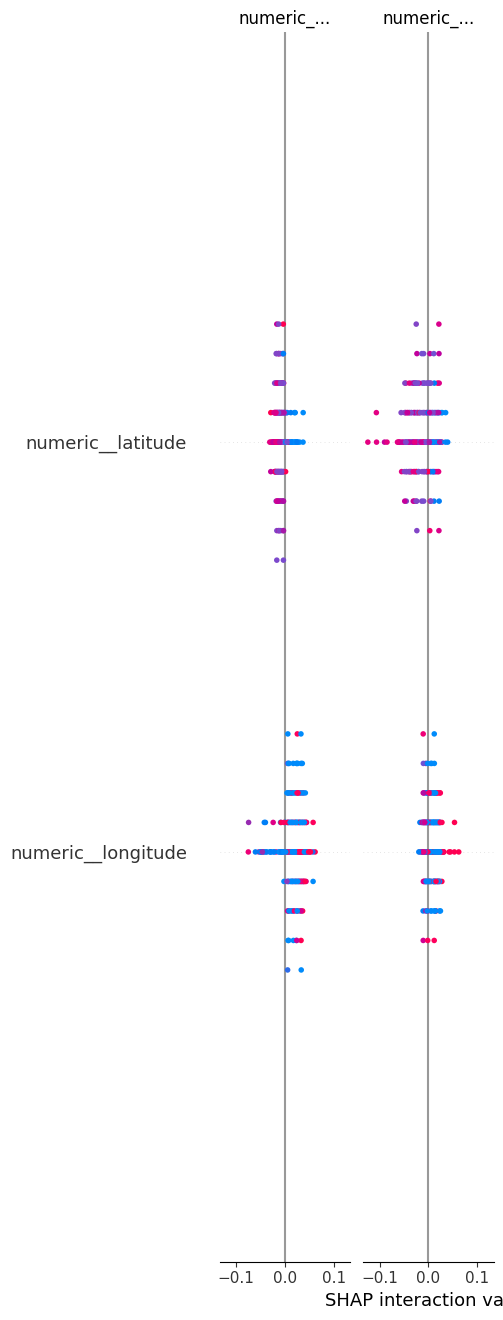

In [25]:
explainer = shap.TreeExplainer(final_random_forest)

shap_values = explainer.shap_values(X_test_processed)

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)

Actual outcome: 1
Predicted outcome: 1


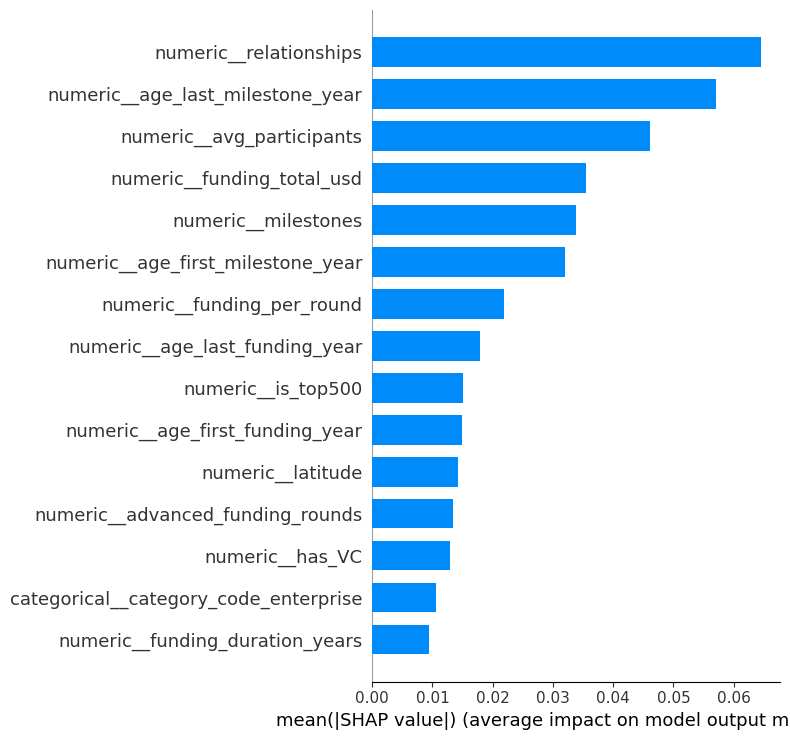

In [26]:
sample_position = 0

if isinstance(shap_values, list):
    acquired_shap_values = shap_values[1]
elif shap_values.ndim == 3:
    acquired_shap_values = shap_values[:, :, 1]
else:
    acquired_shap_values = shap_values

print("Actual outcome:", y_test.iloc[sample_position])
print(
    "Predicted outcome:",
    best_final_model.predict(X_test.iloc[[sample_position]])[0]
)

shap.summary_plot(
    acquired_shap_values[
        sample_position:sample_position + 1
    ],
    X_test_processed[
        sample_position:sample_position + 1
    ],
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)

In [27]:
numeric_defaults = X.select_dtypes(
    include=["int64", "float64"]
).median().to_dict()

categorical_defaults = X.select_dtypes(
    include=["object"]
).mode().iloc[0].to_dict()

input_defaults = {
    **numeric_defaults,
    **categorical_defaults
}

final_model_bundle = {
    "pipeline": best_final_model,
    "feature_columns": X.columns.tolist(),
    "defaults": input_defaults,
    "model_name": best_final_model_name
}

joblib.dump(
    final_model_bundle,
    "../models/startup_shield_final_bundle.pkl"
)

print("Final Streamlit model bundle saved successfully.")

Final Streamlit model bundle saved successfully.


In [28]:
final_model_bundle = {
    "pipeline": best_final_model,
    "feature_columns": X.columns.tolist(),
    "defaults": input_defaults,
    "model_name": best_final_model_name,
    "metrics": final_results_df.to_dict(orient="records")
}

joblib.dump(
    final_model_bundle,
    "../models/startup_shield_final_bundle.pkl"
)

['../models/startup_shield_final_bundle.pkl']